REPORTERÍA GERENCIAL AUTOMATIZADA ---- ENERGÍA POR SEDES

In [1]:
# LIBRERÍAS
%pip install pandas matplotlib jinja2 python-docx 

   ---------------------------------------- 0.0/253.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/253.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/253.0 kB 445.2 kB/s eta 0:00:01
   -------------- ------------------------ 92.2/253.0 kB 751.6 kB/s eta 0:00:01
   --------------------- ---------------- 143.4/253.0 kB 853.3 kB/s eta 0:00:01
   ---------------------------------------- 253.0/253.0 kB 1.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.2/4.0 MB 15.0 MB/s eta 0:00:01
   -- ------------------------------------- 0.3/4.0 MB 5.2 MB/s eta 0:00:01
   --- ------------------------------------ 0.4/4.0 MB 2.9 MB/s eta 0:00:02
   --- ------------------------------------ 0.4/4.0 MB 2.4 MB/s eta 0:00:02
   ---- ----------------------------------- 0.5/4.0 MB 2.2 MB/s eta 0:00:02
   ------ --------------------------------- 0.7/4.0 MB 2.5 MB/s eta 0:00:02
   --------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\galle\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


IMPORTACIÓN Y RUTAS

In [2]:
import hashlib, json, shutil, subprocess, sys, tempfile
from pathlib import Path
import pandas as pd

from Configuracion import DOC_ANALISIS, DOC_RESULTADOS, DT_DATASET, DT_PROCESADOS, DT_VISTA, DOC_REPORTERIA

CSV = DT_DATASET / "operacion_sedes.csv"
REPORTERIA = DOC_REPORTERIA
print("CSV de entrada :", CSV)
print("Carpeta salida :", REPORTERIA)

CSV de entrada : ..\Datos\Datasets\operacion_sedes.csv
Carpeta salida : ..\Documentacion\Reporteria


PLANTILLA HTML

In [3]:
PLANTILLA = r'''
<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="UTF-8">
<title>{{ titulo }}</title>
<style>
    body { font-family: Arial, Helvetica, sans-serif; color: #2b2b2b; max-width: 860px; margin: 30px auto; padding: 0 16px; line-height: 1.5; }
    h1 { color: #1b5e20; border-bottom: 3px solid #1b5e20; padding-bottom: 8px; }
    h2 { color: #1b5e20; margin-top: 28px; }
    .periodo { color: #666; }
    .kpis { display: flex; gap: 12px; flex-wrap: wrap; margin: 16px 0; }
    .kpi { flex: 1 1 200px; background: #eef7ee; border-left: 5px solid #2e7d32; padding: 12px; border-radius: 4px; }
    .kpi .n { font-size: 12px; text-transform: uppercase; color: #555; }
    .kpi .v { font-size: 26px; font-weight: bold; color: #1b5e20; }
    .kpi .u { font-size: 12px; color: #777; }
    .kpi.rojo { background: #fdeeee; border-color: #c0392b; } .kpi.rojo .v { color: #c0392b; }
    img { max-width: 100%; border: 1px solid #ddd; border-radius: 4px; }
    .caja { padding: 10px 14px; border-radius: 4px; margin: 8px 0; }
    .hallazgo { background: #fff4e5; border-left: 5px solid #e67e22; }
    .reco { background: #e8f1fb; border-left: 5px solid #2980b9; }
    .limit { background: #fff6dd; border-left: 5px solid #f1c40f; }
    .pie { font-size: 11px; color: #777; margin-top: 34px; border-top: 1px solid #ddd; padding-top: 8px; word-break: break-all; }
</style>
</head>
<body>
    <h1>{{ titulo }}</h1>
    <p class="periodo"><b>Periodo:</b> {{ periodo }} &nbsp;|&nbsp; <b>Generado:</b> {{ fecha_generacion }}</p>

    <h2>Indicadores clave</h2>
    <div class="kpis">
        {% for nombre, valor, unidad in tarjetas %}
        <div class="kpi{% if nombre == 'Déficit' %} rojo{% endif %}"><div class="n">{{ nombre }}</div><div class="v">{{ valor }}</div><div class="u">{{ unidad }}</div></div>
        {% endfor %}
    </div>

    <h2>Gráfico</h2>
    <img src="{{ grafico }}" alt="Generación vs demanda por sede">

    <h2>Hallazgo</h2>
    <div class="caja hallazgo">{{ hallazgo }}</div>

    <h2>Recomendación</h2>
    <div class="caja reco">{{ recomendacion }}</div>

    <h2>Limitación</h2>
    <div class="caja limit">{{ limitacion }}</div>

    <div class="pie">
    Fuente: {{ fuente }} &nbsp;|&nbsp; Registros de entrada: {{ "{:,}".format(registros) }}<br>
    SHA-256 de la fuente: {{ sha256 }}<br>
    Déficit = {{ definicion }}. Informe generado automáticamente por generar_reporte.py.
</div>
</body>
</html>
'''

(REPORTERIA / "plantilla.html").write_text(PLANTILLA, encoding="utf-8")
print("plantilla.html escrita")

plantilla.html escrita


generar_reporte.py

In [4]:
SCRIPT = r'''

import argparse
import base64
import hashlib
import json
from datetime import datetime
from pathlib import Path

import matplotlib
matplotlib.use("Agg")                       
import matplotlib.pyplot as plt
import pandas as pd
from docx import Document
from docx.shared import Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
from jinja2 import Environment, FileSystemLoader

AQUI = Path(__file__).resolve().parent                      

RAIZ = AQUI.parent                                          

CSV_DEFECTO = RAIZ / "Datos" / "Datasets" / "operacion_sedes.csv"
COLUMNAS = ["fecha", "sede_id", "region", "generacion_kwh", "demanda_kwh", "evento_programado"]


DEFINICION_DEFICIT = "suma por sede-día de max(demanda_kwh - generacion_kwh, 0)"


def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()


def cargar(ruta_csv):
    df = pd.read_csv(ruta_csv, parse_dates=["fecha"])
    faltan = [c for c in COLUMNAS if c not in df.columns]
    if faltan:
        raise ValueError(f"Faltan columnas en el CSV: {faltan}")
    if df[COLUMNAS].isna().any().any():
        raise ValueError("El CSV tiene valores nulos en columnas requeridas")
    if (df[["generacion_kwh", "demanda_kwh"]] < 0).any().any():
        raise ValueError("Hay valores negativos de generacion o demanda")
    if df.duplicated(["fecha", "sede_id"]).any():
        raise ValueError("Hay filas duplicadas (misma fecha y sede)")
    return df


def calcular(df):
    df = df.assign(deficit_kwh=(df["demanda_kwh"] - df["generacion_kwh"]).clip(lower=0))
    kpis = {
        "energia_total_kwh": round(float(df["generacion_kwh"].sum()), 2),
        "demanda_total_kwh": round(float(df["demanda_kwh"].sum()), 2),
        "deficit_total_kwh": round(float(df["deficit_kwh"].sum()), 2),
    }
    por_sede = (df.groupby(["sede_id", "region"], as_index=False)
                    .agg(generacion=("generacion_kwh", "sum"), demanda=("demanda_kwh", "sum"),
                    deficit=("deficit_kwh", "sum")))
    por_sede["pct_del_deficit"] = por_sede["deficit"] / kpis["deficit_total_kwh"] * 100
    por_sede["pct_de_la_demanda"] = por_sede["demanda"] / kpis["demanda_total_kwh"] * 100
    por_sede["pct_propio_sin_cubrir"] = por_sede["deficit"] / por_sede["demanda"] * 100
    return kpis, por_sede.sort_values("deficit", ascending=False).reset_index(drop=True)


def fmt(x):
    return f"{x:,.0f}"


def textos(df, kpis, por_sede):
    s = por_sede.iloc[0]
    n_dias = df["fecha"].nunique()
    cobertura = 100 * (1 - kpis["deficit_total_kwh"] / kpis["demanda_total_kwh"]) 
    hallazgo = (f"La sede {s['sede_id']} ({s['region']}) concentra {s['pct_del_deficit']:.1f}% del déficit total "
                f"({fmt(s['deficit'])} kWh) con solo {s['pct_de_la_demanda']:.1f}% de la demanda; "
                f"deja sin cubrir {s['pct_propio_sin_cubrir']:.1f}% de su propia demanda. "
                f"La cobertura global de la demanda es {cobertura:.2f}% (100 x (1 - déficit / demanda)).")
    recomendacion = (f"Priorizar la sede {s['sede_id']} para ampliar generación o respaldo energético y "
                    f"revisar también {por_sede.iloc[1]['sede_id']} (segundo mayor déficit); "
                    f"meta: reducir su déficit y darle seguimiento semanal con el KPI de déficit.")
    limitacion = (f"El análisis cubre {n_dias} días ({df['fecha'].min():%d/%m/%Y} a {df['fecha'].max():%d/%m/%Y}) y solo "
                    f"energía en kWh: no incluye capacidad instalada, costos ni almacenamiento, y el déficit no compensa "
                    f"excedentes de unas sedes con faltantes de otras.")
    return hallazgo, recomendacion, limitacion


def grafico(por_sede, ruta_png):
    d = por_sede.sort_values("sede_id")
    x = range(len(d))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar([i - 0.2 for i in x], d["generacion"] / 1000, width=0.4, label="Generación", color="#2e7d32")
    ax.bar([i + 0.2 for i in x], d["demanda"] / 1000, width=0.4, label="Demanda", color="#c0392b")
    top = por_sede.iloc[0]["sede_id"]
    for i, (sede, deficit) in enumerate(zip(d["sede_id"], d["deficit"])):
        ax.text(i, max(d["demanda"].max(), d["generacion"].max()) / 1000 * 1.03, f"{deficit/1000:,.1f}",
                ha="center", fontsize=9, fontweight="bold" if sede == top else "normal",
                color="#c0392b" if sede == top else "#555")
    ax.set_xticks(list(x)); ax.set_xticklabels(d["sede_id"])
    ax.set_ylabel("Energía acumulada (MWh)"); ax.set_xlabel("Sede")
    ax.set_title("Generación vs. demanda por sede (número sobre cada sede = déficit en MWh)", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
    fig.tight_layout(); fig.savefig(ruta_png, dpi=150); plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", default=str(CSV_DEFECTO), help="ruta de operacion_sedes.csv")
    ap.add_argument("--salida", default=str(AQUI), help="carpeta donde se escriben los productos")
    a = ap.parse_args()
    ruta_csv, salida = Path(a.csv), Path(a.salida)
    salida.mkdir(parents=True, exist_ok=True)

    df = cargar(ruta_csv)
    kpis, por_sede = calcular(df)
    hallazgo, recomendacion, limitacion = textos(df, kpis, por_sede)
    periodo = f"{df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}"
    ahora = datetime.now()

    # 1) grafico.png
    png = salida / "grafico.png"
    grafico(por_sede, png)

    # 2) reporte_kpis.csv 
    pd.DataFrame({"indicador": list(kpis), "valor": list(kpis.values())}).to_csv(
        salida / "reporte_kpis.csv", index=False)

    # 3) metadatos.json 
    sha = sha256_archivo(ruta_csv)
    try:
        fuente = ruta_csv.resolve().relative_to(RAIZ).as_posix()
    except ValueError:
        fuente = ruta_csv.name
    meta = {"fuente": fuente, "registros_entrada": int(len(df)), "sha256_fuente": sha,
            "periodo": periodo, "definicion_deficit": DEFINICION_DEFICIT,
            "kpis": kpis, "generado_en": ahora.isoformat(timespec="seconds"),
            "generado_por": "generar_reporte.py"}
    (salida / "metadatos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

    # 4) informe.html
    titulo = "Informe gerencial de energía por sedes"
    tarjetas = [("Energía generada", fmt(kpis["energia_total_kwh"]), "kWh"),
                ("Demanda", fmt(kpis["demanda_total_kwh"]), "kWh"),
                ("Déficit", fmt(kpis["deficit_total_kwh"]), "kWh")]
    img64 = "data:image/png;base64," + base64.b64encode(png.read_bytes()).decode()
    env = Environment(loader=FileSystemLoader(str(AQUI)), autoescape=True)
    html = env.get_template("plantilla.html").render(
        titulo=titulo, periodo=periodo, fecha_generacion=ahora.strftime("%d/%m/%Y %H:%M"), tarjetas=tarjetas,
        grafico=img64, hallazgo=hallazgo, recomendacion=recomendacion, limitacion=limitacion,
        fuente=fuente, registros=len(df), sha256=sha, definicion=DEFINICION_DEFICIT)
    (salida / "informe.html").write_text(html, encoding="utf-8")

    # 5) informe.docx
    doc = Document()
    doc.add_heading(titulo, 0).alignment = WD_ALIGN_PARAGRAPH.CENTER
    doc.add_paragraph(f"Periodo: {periodo}  |  Generado: {ahora:%d/%m/%Y %H:%M}")
    doc.add_heading("Indicadores clave", 1)
    t = doc.add_table(rows=1, cols=2); t.style = "Light Grid Accent 1"
    t.rows[0].cells[0].text, t.rows[0].cells[1].text = "Indicador", "Valor"
    for nombre, valor, unidad in tarjetas:
        c = t.add_row().cells; c[0].text, c[1].text = nombre, f"{valor} {unidad}"
    doc.add_heading("Gráfico", 1); doc.add_picture(str(png), width=Inches(6))
    for encabezado, texto in (("Hallazgo", hallazgo), ("Recomendación", recomendacion), ("Limitación", limitacion)):
        doc.add_heading(encabezado, 1); doc.add_paragraph(texto)
    p = doc.add_paragraph(f"Fuente: {fuente} | registros: {len(df):,} | SHA-256: {sha}")
    doc.save(str(salida / "informe.docx"))

    print(f"OK | {len(df):,} registros | periodo {periodo}")
    for k, v in kpis.items():
        print(f"   {k}: {v:,.2f}")
    print("Generados en", salida)


if __name__ == "__main__":
    main()
'''

(REPORTERIA / "generar_reporte.py").write_text(SCRIPT, encoding="utf-8")
print("generar_reporte.py escrito")

generar_reporte.py escrito


EJECUTAR SCRIPT

In [5]:
def ejecutar(csv=CSV, salida=None):
    cmd = [sys.executable, str(REPORTERIA / "generar_reporte.py")]
    if csv:    cmd += ["--csv", str(csv)]
    if salida: cmd += ["--salida", str(salida)]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace")
    print(r.stdout)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)

ejecutar()

OK | 1,620 registros | periodo 01/01/2026 al 29/06/2026
   energia_total_kwh: 2,913,623.55
   demanda_total_kwh: 3,146,866.67
   deficit_total_kwh: 286,904.20
Generados en C:\Users\galle\Desktop\IA Datos\Jupyter\Evaluacion_Practica_Grupal_IDS221\Documentacion\Reporteria



VERIFICAR LOS PRODUCTOS

OK      generar_reporte.py       8.3 KB
OK      plantilla.html           2.4 KB
OK      informe.html            64.8 KB
OK      informe.docx            76.0 KB
OK      grafico.png             46.2 KB
OK      reporte_kpis.csv         0.1 KB
OK      metadatos.json           0.5 KB

--- reporte_kpis.csv ---
indicador,valor
energia_total_kwh,2913623.55
demanda_total_kwh,3146866.67
deficit_total_kwh,286904.2

--- metadatos.json ---
{
  "fuente": "operacion_sedes.csv",
  "registros_entrada": 1620,
  "sha256_fuente": "9c28479ba39e4204b20bacdb23341e155ad1b9d8d517338906ae540b005520cb",
  "periodo": "01/01/2026 al 29/06/2026",
  "definicion_deficit": "suma por sede-día de max(demanda_kwh - generacion_kwh, 0)",
  "kpis": {
    "energia_total_kwh": 2913623.55,
    "demanda_total_kwh": 3146866.67,
    "deficit_total_kwh": 286904.2
  },
  "generado_en": "2026-10-15T20:57:10",
  "generado_por": "generar_reporte.py"
}

sha256_fuente coincide con operacion_sedes.csv


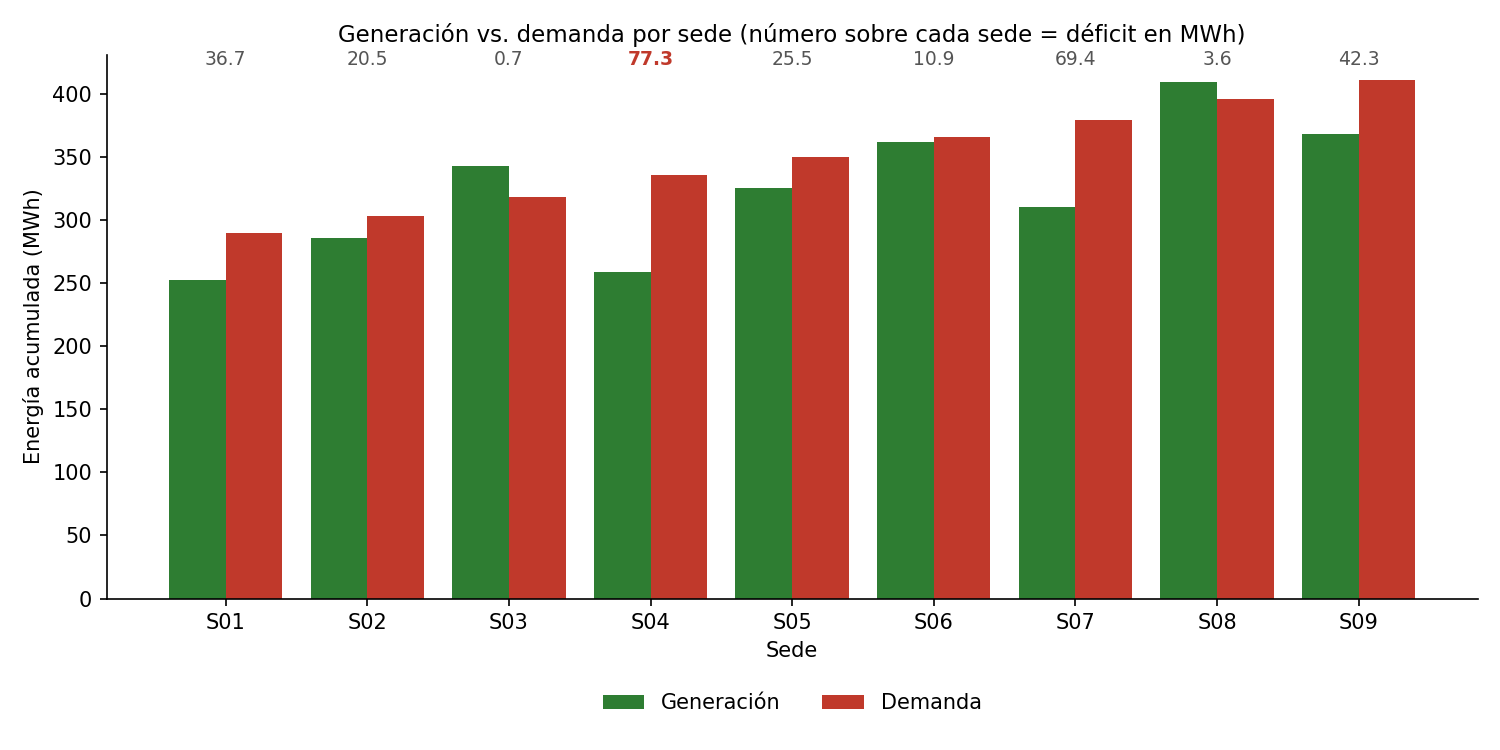

In [6]:
ESPERADOS = ["generar_reporte.py", "plantilla.html", "informe.html", "informe.docx",
            "grafico.png", "reporte_kpis.csv", "metadatos.json"]
for nombre in ESPERADOS:
    p = REPORTERIA / nombre
    print(("OK      " if p.exists() else "FALTA   ") + f"{nombre:<20}" + (f"{p.stat().st_size/1024:>8.1f} KB" if p.exists() else ""))

print("\n--- reporte_kpis.csv ---")
print((REPORTERIA / "reporte_kpis.csv").read_text(encoding="utf-8"))

meta = json.loads((REPORTERIA / "metadatos.json").read_text(encoding="utf-8"))
print("--- metadatos.json ---")
print(json.dumps(meta, indent=2, ensure_ascii=False))

sha_real = hashlib.sha256(CSV.read_bytes()).hexdigest()
assert meta["sha256_fuente"] == sha_real, "El sha256 de metadatos NO coincide con la fuente"
print("\nsha256_fuente coincide con operacion_sedes.csv")

from IPython.display import Image, display
display(Image(filename=str(REPORTERIA / "grafico.png"), width=700))

CONCORDANCIA CON LA INFORMACIÓN DEL DASHBOARD

In [7]:
IND = DOC_RESULTADOS / "indicadores.csv"
if IND.exists():
    dash = pd.read_csv(IND).set_index("indicador")["valor"]
    rep = pd.read_csv(REPORTERIA / "reporte_kpis.csv").set_index("indicador")["valor"]
    tabla = pd.DataFrame({"informe": rep, "dashboard": dash.reindex(rep.index)})
    tabla["coincide"] = (tabla["informe"] - tabla["dashboard"]).abs() < 0.01
    print(tabla.to_string())
    print("Coinciden los 3 KPIs con el dashboard:", bool(tabla["coincide"].all()))
else:
    print("No se encontró", IND, "- omitido.")

                      informe   dashboard  coincide
indicador                                          
energia_total_kwh  2913623.55  2913623.55      True
demanda_total_kwh  3146866.67  3146866.67      True
deficit_total_kwh   286904.20   286904.20      True
Coinciden los 3 KPIs con el dashboard: True


DEMOSTRACIÓN 1

In [8]:
destino_1 = REPORTERIA / "Reporteria_ejecucion_1"
shutil.copytree(REPORTERIA, destino_1,
                ignore=shutil.ignore_patterns("Reporteria_ejecucion_*"),
                dirs_exist_ok=True)
print("Primera ejecución guardada en", destino_1)

Primera ejecución guardada en ..\Documentacion\Reporteria\Reporteria_ejecucion_1


DEMOSTRACIÓN 2: REGENERACIÓN DEL INFORME

In [9]:
import pandas as pd
kpis_original = pd.read_csv(REPORTERIA / "reporte_kpis.csv")

# 1) Misma entrada -> misma salida
ejecutar()
kpis_repetido = pd.read_csv(REPORTERIA / "reporte_kpis.csv")
print("¿KPIs idénticos al volver a ejecutar?", kpis_original.equals(kpis_repetido))

# 2) Entrada distinta
tmp = Path(tempfile.mkdtemp())
pd.read_csv(CSV).iloc[:-90].to_csv(tmp / "operacion_sedes.csv", index=False)
ejecutar(csv=tmp / "operacion_sedes.csv", salida=tmp / "salida")

kpis_nuevo = pd.read_csv(tmp / "salida" / "reporte_kpis.csv")
meta_nuevo = json.loads((tmp / "salida" / "metadatos.json").read_text(encoding="utf-8"))
comparacion = kpis_original.merge(kpis_nuevo, on="indicador", suffixes=("_original", "_actualizado"))
print(comparacion.to_string(index=False))
print(f"\nregistros_entrada: {meta['registros_entrada']:,} -> {meta_nuevo['registros_entrada']:,}")
print("sha256 cambió:", meta["sha256_fuente"] != meta_nuevo["sha256_fuente"])

destino_2 = REPORTERIA / "Reporteria_ejecucion_2"
shutil.copytree(tmp / "salida", destino_2, dirs_exist_ok=True)
shutil.rmtree(tmp)

OK | 1,620 registros | periodo 01/01/2026 al 29/06/2026
   energia_total_kwh: 2,913,623.55
   demanda_total_kwh: 3,146,866.67
   deficit_total_kwh: 286,904.20
Generados en C:\Users\galle\Desktop\IA Datos\Jupyter\Evaluacion_Practica_Grupal_IDS221\Documentacion\Reporteria

¿KPIs idénticos al volver a ejecutar? True
OK | 1,530 registros | periodo 01/01/2026 al 19/06/2026
   energia_total_kwh: 2,744,617.65
   demanda_total_kwh: 2,961,376.34
   deficit_total_kwh: 268,600.50
Generados en C:\Users\galle\AppData\Local\Temp\tmp54w0g2hp\salida

        indicador  valor_original  valor_actualizado
energia_total_kwh      2913623.55         2744617.65
demanda_total_kwh      3146866.67         2961376.34
deficit_total_kwh       286904.20          268600.50

registros_entrada: 1,620 -> 1,530
sha256 cambió: True


## JUSTIFICACIÓN TÉNCICA

Al regenerar el informe cambian los KPIs (energía 2,913,624 kWh, demanda 3,146,867 kWh y déficit 286,904 kWh), el gráfico, el hallazgo, el periodo y la fecha, porque generar_reporte.py recalcula todo con Pandas desde operacion_sedes.csv, sin ingresar cifras a mano. La concordancia con el dashboard la prueban registros_entrada (1,620) y sha256_fuente, que muestran que ambos usaron el mismo archivo, y los 3 KPIs coinciden con indicadores.csv. La principal limitación operativa es que el informe solo está tan actualizado como el CSV, que hay que reemplazar y volver a ejecutar, y que el déficit se mide por sede-día sin compensar excedentes.